# Small local LLMs for predictive-maintenance knowledge: prompting vs RAG
### Experiment 1 for the ICAIEA 2026 paper, accuracy runs on a Colab GPU

**What this notebook does**

It asks small, open-weight language models (the kind a firm can run on its own computer, so no data leaves the building) multiple-choice questions from **FailureSensorIQ**, IBM's benchmark on which sensors detect which failure modes in 10 industrial assets. It compares four ways of using each model:

| Condition | What the model gets |
|---|---|
| `zero_shot` | Just the question and options; answers with a letter |
| `cot` | Same, but told to reason step by step first ("chain of thought") |
| `rag` | Relevant notes retrieved from the plant's condition-monitoring documentation, then the question |
| `rag_cot` | Retrieved notes plus step-by-step reasoning (optional) |

It also tests **robustness**, using two altered versions of every question (options shuffled; question reworded), and **documentation completeness**, running RAG with 100% and 50% of the documentation available.

**How to use it**
1. `Runtime → Change runtime type → T4 GPU` → Save.
2. Check the **Settings** cell below, then run all cells from top to bottom (`Runtime → Run all`).
3. Results are saved to your Google Drive as they are produced. If Colab disconnects, reconnect and **run all again**. It skips everything already done.

**Rough run times on a free T4** (1,000 questions, one model): letter-only conditions take roughly 10–25 minutes each. Reasoning conditions write a few hundred words per question and take several times longer. Run the `original` questions first; that's all you need for the abstract.

**Then:** run `fsiq_laptop_benchmark.py` on your laptop to measure speed and memory on low-cost hardware.

*Dataset: Constantinides et al. (2025), FailureSensorIQ, NeurIPS Datasets & Benchmarks, CC BY 4.0.*

## 1. Settings
This is the only cell you normally need to edit. Model tags must match the [Ollama library](https://ollama.com/library) exactly; use the same tags you run on your laptop, so both machines load the identical model file.

In [ ]:
# --- Models to test ------------------------------------------------------
# Small models that also fit on an 8 GB laptop (so the laptop timings in the
# paper correspond to the same models). Optionally add a bigger "reference"
# model that only runs on the GPU, e.g. "qwen3.5:9b", to show what an
# upgrade would buy.
MODELS = ["qwen3.5:2b", "qwen3.5:4b", "gemma4:e2b"]

# --- How many questions --------------------------------------------------
# 1,000 of the 2,667 questions, sampled so every asset keeps its share.
# Use 50 for a quick trial run first.
SAMPLE_SIZE = 1000

# --- What to run ---------------------------------------------------------
# Conditions for the original questions (the main comparison).
CONDITIONS_ORIGINAL = ["zero_shot", "cot", "rag"]       # add "rag_cot" if time allows
# Conditions for the shuffled / reworded versions (robustness test).
# Leave empty ([]) to skip robustness for now - e.g. before the abstract.
CONDITIONS_PERTURBED = ["zero_shot", "rag"]
# Documentation completeness levels for the RAG conditions:
# 1.0 = the full ISO table, 0.5 = half the faults undocumented.
RAG_COVERAGES = [1.0, 0.5]
RAG_TOP_K = 4            # passages pasted into the prompt per question

# --- Where to save (Google Drive, so results survive disconnects) --------
DRIVE_DIR = "/content/drive/MyDrive/ICAIEA2026_FailureSensorIQ"

# --- Speed ---------------------------------------------------------------
WORKERS = 4              # questions sent to the GPU at the same time

## 2. Connect Google Drive and check the GPU
You'll be asked to allow access to your Drive. `nvidia-smi` should show a **Tesla T4**; if it says *command not found*, the GPU runtime isn't on (see step 1 at the top).

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
RESULTS_DIR = os.path.join(DRIVE_DIR, "results")   # one CSV per experimental run
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Saving to:", DRIVE_DIR)

!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Saving to: /content/drive/MyDrive/ICAIEA2026_FailureSensorIQ
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 3. Install Python packages and download the benchmark
`rank_bm25` is the keyword-search library used for retrieval. The benchmark is downloaded straight from IBM's GitHub repository.

In [ ]:
!pip -q install rank_bm25 openpyxl
REPO_DIR = "/content/FailureSensorIQ"
import subprocess
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/IBM/FailureSensorIQ", REPO_DIR], check=True)
print("Benchmark files ready:", os.path.exists(os.path.join(REPO_DIR, "eval_data")))

Benchmark files ready: True


## 4. Install and start Ollama on the Colab GPU
This is the same Ollama you use on your laptop, running here as a background server. `OLLAMA_NUM_PARALLEL` lets it answer several questions at once on the GPU.

In [ ]:
!sudo apt-get -qq install -y zstd pciutils lshw > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1

import subprocess, time, requests

def start_ollama():
    """Start the Ollama server in the background and wait until it answers."""
    env = os.environ.copy()
    env["OLLAMA_NUM_PARALLEL"] = str(WORKERS)
    env["OLLAMA_MAX_LOADED_MODELS"] = "1"      # one model in GPU memory at a time
    log = open("/content/ollama.log", "w")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=subprocess.STDOUT, env=env)
    for _ in range(60):
        try:
            requests.get("http://localhost:11434", timeout=2)
            print("Ollama server is running.")
            return
        except requests.exceptions.ConnectionError:
            time.sleep(1)
    raise RuntimeError("Ollama did not start - look at /content/ollama.log")

try:
    requests.get("http://localhost:11434", timeout=2)
    print("Ollama already running.")
except requests.exceptions.ConnectionError:
    start_ollama()

Ollama already running.


## 5. Download the models
Each model is downloaded once per Colab session (about 2–4 GB each; this takes a few minutes).

In [ ]:
for m in MODELS:
    print("Pulling", m, "...")
    subprocess.run(["ollama", "pull", m], check=True, stdout=subprocess.DEVNULL)
!ollama list

Pulling qwen3.5:2b ...
Pulling qwen3.5:4b ...
Pulling gemma4:e2b ...
NAME          ID              SIZE      MODIFIED               
gemma4:e2b    b37049369adf    4.6 GB    Less than a second ago    
qwen3.5:4b    d8b0f5e9760c    3.3 GB    49 seconds ago            
qwen3.5:2b    0689d44085e0    2.7 GB    About a minute ago        


## 6. The experiment code
The next five cells define the building blocks. They are **identical** to the code in `fsiq_laptop_benchmark.py`, so the laptop measures exactly the same thing. Read the comments to see how each part works. Running these cells only defines functions; nothing is sent to a model yet.

### 6a. Loading the questions

In [ ]:
# =====================================================================
# PART A - LOADING THE FAILURESENSORIQ QUESTIONS
# =====================================================================
# FailureSensorIQ (IBM Research, NeurIPS 2025) has 2,667 single-answer
# multiple-choice questions about which sensors detect which failure
# modes, across 10 industrial assets. Licence: CC BY 4.0 - cite the paper.
#
# The same 2,667 questions come in three versions. All three share the
# same question "id", so we can line them up and check whether a model
# answers the SAME question correctly in every version:
#   original     - the questions as written
#   simple_pert  - options shuffled and labels changed from A,B,C to P,Q,R
#   complex_pert - as above, plus the question reworded by another LLM
# A model that really "knows" the answer should get all three right.
# A model that is guessing or relying on option position will not.
# =====================================================================
import json
import os
import random

import pandas as pd

VARIANT_FILES = {
    "original":     "eval_data/fmsr_processed/fmsr_filtered_data_all.jsonl",
    "simple_pert":  "eval_data/fmsr_processed/fmsr_filtered_perturbed_data_all_simple.jsonl",
    "complex_pert": "eval_data/fmsr_processed/fmsr_filtered_perturbed_data_all_llama.jsonl",
}


def read_jsonl(path):
    """Read a .jsonl file (one JSON object per line) into a list of dicts."""
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_questions(repo_dir, variant="original"):
    """Load one version of the questions as a table (pandas DataFrame).

    Each row is one question with these columns:
      id        - question id (identical across the three versions)
      asset     - e.g. "electric motor" (perturbed files lack this, so we
                  copy it over from the original file using the id)
      question  - the question text
      labels    - option letters, e.g. ["A","B","C","D","E"] or ["P","Q",...]
      options   - option texts, in the same order as labels
      answer    - the letter of the correct option
      n_options - number of options (2 to 5); random guessing = 1/n_options
    """
    original = read_jsonl(os.path.join(repo_dir, VARIANT_FILES["original"]))
    asset_by_id = {r["id"]: r["asset_name"] for r in original}

    if variant == "original":
        raw = original
    else:
        raw = read_jsonl(os.path.join(repo_dir, VARIANT_FILES[variant]))

    records = []
    for r in raw:
        # Perturbed files write labels as "P)", "Q)" ... so strip the bracket.
        labels = [lab.strip().rstrip(")").strip() for lab in r["option_ids"]]
        correct_positions = [i for i, flag in enumerate(r["correct"]) if flag]
        assert len(correct_positions) == 1, "expected exactly one correct option"
        records.append({
            "id": int(r["id"]),
            "asset": asset_by_id[r["id"]],
            "question": r["question"].strip(),
            "labels": labels,
            "options": [str(o).strip() for o in r["options"]],
            "answer": labels[correct_positions[0]],
            "n_options": len(labels),
        })
    return pd.DataFrame(records)


def stratified_sample(df, n, seed=42):
    """Pick n questions so each asset keeps its share of the full dataset.

    Example: power transformers are 544 of 2,667 questions (20.4%), so a
    1,000-question sample gets about 204 of them. The fixed seed means you
    get the SAME sample every time, on Colab and on your laptop.
    """
    if n >= len(df):
        return df.copy()
    shares = df["asset"].value_counts() / len(df)
    exact = shares * n
    counts = exact.astype(int)
    # Hand out the remaining places to the assets with the largest
    # fractional parts, so the counts add up to exactly n.
    remainder = int(n - counts.sum())
    for asset in (exact - counts).sort_values(ascending=False).index[:remainder]:
        counts[asset] += 1
    rng = random.Random(seed)
    picked = []
    for asset, k in counts.items():
        ids = sorted(df.loc[df["asset"] == asset, "id"].tolist())
        picked.extend(rng.sample(ids, int(k)))
    return df[df["id"].isin(picked)].sort_values("id").reset_index(drop=True)

### 6b. Knowledge base and retrieval (RAG)

In [ ]:
# =====================================================================
# PART B - THE KNOWLEDGE BASE AND RETRIEVER (the "R" in RAG)
# =====================================================================
# RAG = Retrieval-Augmented Generation. Before asking the model a
# question, we search a document collection for the most relevant
# passages and paste them into the prompt. The model then answers using
# those notes, without needing the knowledge stored in its own weights.
#
# Our document collection is the ISO 17359 condition-monitoring table
# that IBM released with FailureSensorIQ (file iso_sensors.xlsx). It has
# one sheet per asset: rows are faults, columns are sensors, and an "X"
# means "this sensor can detect this fault". In the paper we frame this
# as "the firm's own condition-monitoring documentation". Many plants
# keep exactly this kind of FMEA/CM table.
#
# IMPORTANT for the paper: the questions were generated from this same
# table, so RAG with 100% of the table is a best case ("complete
# documentation"). That is why we also run a "coverage" setting that
# randomly drops some fault rows (e.g. coverage=0.5 keeps half). It
# shows how accuracy falls when the firm's documentation is incomplete,
# which is the realistic case.
#
# We turn the table into short text passages ("chunks") of two kinds:
#   fault chunk : asset + fault -> which sensors detect it / which don't
#   sensor chunk: asset + sensor -> which faults it indicates / which not
# Both are needed because questions run in both directions.
#
# Retrieval uses BM25, a classic keyword-matching search algorithm (the
# same family search engines used before neural search). It needs no
# GPU, no extra model and runs instantly on a CPU laptop, which suits a
# low-cost deployment.
#
# We search only each passage's TITLE (e.g. "pump | fault: bearing
# wear"), using the question text as the query. Searching the full
# passages works worse, because every passage also lists many sensors
# and faults in its "NOT associated" part, which confuses keyword
# matching. Tested on the 1,000-question sample, title search puts the
# right passage in the top 4 for 99% of original questions and 97.5% of
# reworded ones (vs about 95% for full-text search). Worth one sentence
# in the Methods section.
# =====================================================================
import random
import re

import pandas as pd
from rank_bm25 import BM25Okapi

KB_FILE = "LLM-Embeddings/data/raw/iso_sensors.xlsx"
OVERVIEW_SHEET = "Condition Monitoring Parameter"


def _clean(text):
    """Lower-case and tidy a table label, e.g. 'Rotor windings fault '."""
    return re.sub(r"\s+", " ", str(text)).strip().lower()


def _sheet_to_asset(sheet_name, asset_names):
    """Match an Excel sheet name to the asset name used in the questions.

    Excel cuts sheet names at 31 characters, so the sheet for
    "reciprocating internal combustion engine" is called
    "reciprocating internal combusti". We match by prefix.
    """
    s = _clean(sheet_name)
    for asset in asset_names:
        if asset == s or asset.startswith(s):
            return asset
    return None


def build_knowledge_chunks(xlsx_path, asset_names, coverage=1.0, seed=0):
    """Turn the ISO table into a list of text passages for retrieval.

    coverage: fraction of fault rows to keep (1.0 = full documentation,
              0.5 = half the faults are undocumented). Rows are dropped
              at random but reproducibly (fixed seed).
    """
    xl = pd.ExcelFile(xlsx_path)
    rng = random.Random(seed)
    chunks = []

    # 1) Overview sheet: which parameters are monitored for each asset.
    overview = xl.parse(OVERVIEW_SHEET)
    for col in overview.columns[1:]:
        asset = _sheet_to_asset(col, asset_names)
        if asset is None:
            continue
        params = [_clean(p) for p, mark in zip(overview.iloc[:, 0], overview[col])
                  if isinstance(mark, str) and mark.strip()]
        chunks.append(f"{asset} | condition-monitoring parameters used for this asset: "
                      + ", ".join(params) + ".")

    # 2) One sheet per asset: fault rows x sensor columns.
    for sheet in xl.sheet_names:
        if sheet == OVERVIEW_SHEET:
            continue
        asset = _sheet_to_asset(sheet, asset_names)
        if asset is None:
            continue
        table = xl.parse(sheet)
        sensors = [_clean(c) for c in table.columns[1:]]

        # Read each fault row: which sensors have an "X".
        rows = []
        for _, r in table.iterrows():
            fault = _clean(r.iloc[0])
            marks = [isinstance(v, str) and v.strip() != "" for v in r.iloc[1:]]
            rows.append((fault, marks))

        # Simulate incomplete documentation by dropping some fault rows.
        if coverage < 1.0:
            keep = max(1, round(len(rows) * coverage))
            rows = rng.sample(rows, keep)

        # Fault chunks: fault -> sensors.
        for fault, marks in rows:
            yes = [s for s, m in zip(sensors, marks) if m]
            no = [s for s, m in zip(sensors, marks) if not m]
            chunks.append(
                f"{asset} | fault: {fault}. Sensors that can detect this fault: "
                f"{', '.join(yes) or 'none listed'}. "
                f"Sensors NOT associated with this fault: {', '.join(no) or 'none'}.")

        # Sensor chunks: sensor -> faults (built only from the kept rows).
        for j, sensor in enumerate(sensors):
            yes = [f for f, marks in rows if marks[j]]
            no = [f for f, marks in rows if not marks[j]]
            chunks.append(
                f"{asset} | sensor: {sensor}. Faults indicated by abnormal {sensor} "
                f"readings: {', '.join(yes) or 'none listed'}. "
                f"Faults NOT indicated by this sensor: {', '.join(no) or 'none'}.")
    return chunks


def _tokenize(text):
    """Split text into lower-case words for BM25 keyword matching."""
    return re.findall(r"[a-z0-9]+", text.lower())


def chunk_title(chunk):
    """The title is everything before the first '. ', e.g.
    'electric motor | fault: bearing damage'."""
    return chunk.split(". ", 1)[0]


class BM25Retriever:
    """Keyword search over the knowledge chunks (matching on titles)."""

    def __init__(self, chunks):
        self.chunks = chunks
        self.bm25 = BM25Okapi([_tokenize(chunk_title(c)) for c in chunks])

    def retrieve(self, query, k=4):
        """Return the k chunks whose titles best match the query text."""
        scores = self.bm25.get_scores(_tokenize(query))
        best = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:k]
        return [self.chunks[i] for i in best]

### 6c. Prompts and reading the model's answer

In [ ]:
# =====================================================================
# PART C - PROMPTS AND ANSWER PARSING
# =====================================================================
# The four experimental conditions differ ONLY in the prompt:
#   zero_shot - question + options, "reply with the letter only"
#   cot       - "chain of thought": reason briefly, then give the letter
#   rag       - retrieved notes + question, "reply with the letter only"
#   rag_cot   - retrieved notes + brief reasoning
# Keeping everything else identical (same model, same settings) means
# any difference in accuracy comes from the method.
#
# !! These prompts are copied word-for-word into the laptop script.
# !! If you change them here, change them there too, or the Colab and
# !! laptop results will not be comparable.
# =====================================================================
import re

SYSTEM_PROMPT = (
    "You are an experienced reliability and condition-monitoring engineer. "
    "You answer multiple-choice questions about industrial assets, their "
    "failure modes and the sensors used to detect them."
)

LETTER_ONLY = ("Reply with only the letter of the correct option "
               "(for example: {example}). Do not explain.")
REASON_THEN_ANSWER = ("Think through the question step by step in a few short "
                      "sentences, then write the final line exactly as "
                      "'Answer: <letter>'.")


def format_options(labels, options):
    """Lay the options out one per line: 'A. vibration'."""
    return "\n".join(f"{lab}. {opt}" for lab, opt in zip(labels, options))


def retrieval_query(row):
    """Text used to search the knowledge base: the question only.
    (Adding the option texts made retrieval worse in testing, because
    options mention sensors/faults from many different passages.)"""
    return row["question"]


def build_messages(row, condition, context_chunks=None):
    """Build the chat messages sent to the model for one question.

    row       - one question (a row of the DataFrame from Part A)
    condition - "zero_shot", "cot", "rag" or "rag_cot"
    context_chunks - retrieved passages (only for the rag conditions)
    """
    parts = []
    if condition.startswith("rag"):
        notes = "\n".join(f"- {c}" for c in (context_chunks or []))
        parts.append("Reference notes from the plant's condition-monitoring "
                     "documentation (they may be incomplete):\n" + notes)
    parts.append("Question: " + row["question"])
    parts.append("Options:\n" + format_options(row["labels"], row["options"]))
    if condition.endswith("cot"):
        parts.append(REASON_THEN_ANSWER)
    else:
        parts.append(LETTER_ONLY.format(example=row["labels"][0]))
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": "\n\n".join(parts)},
    ]


def parse_answer(text, labels, options):
    """Pull the chosen letter out of the model's reply.

    Small models do not always follow instructions exactly, so we try
    several patterns, from most to least specific. Returns None if no
    answer can be found. That counts as WRONG, and we also report the
    parse-failure rate, because "cannot follow the format" is itself a
    finding about small models.
    """
    if not text:
        return None
    valid = set(labels)
    letters = "|".join(re.escape(l) for l in labels)

    # 1) "Answer: B" / "answer is (B)" - take the LAST one (after reasoning).
    #    "answer" may be any case, but the letter must be a capital, so
    #    "the answer is a pressure sensor" is NOT read as option A.
    hits = re.findall(rf"(?i:answer)\s*(?i:is)?\s*[:\-]?\s*\**\(?({letters})\)?(?![A-Za-z])",
                      text)
    hits = [h for h in hits if h in valid]
    if hits:
        return hits[-1]

    # 2) The reply is just a letter ("B", "(B)", "**B**") or starts with
    #    a letter followed by punctuation ("B. vibration", "B) vibration").
    m = re.match(rf"^\**\(?({letters})\)?\**\s*$", text.strip())
    if not m:
        m = re.match(rf"^\**\(?({letters})[.):\-]", text.strip())
    if m:
        return m.group(1)

    # 3) The reply quotes exactly one option's text, e.g. "vibration".
    lowered = text.lower()
    quoted = [lab for lab, opt in zip(labels, options)
              if re.search(rf"\b{re.escape(opt.lower())}\b", lowered)]
    if len(quoted) == 1:
        return quoted[0]
    return None

### 6d. Sending a question to Ollama

In [ ]:
# =====================================================================
# PART D - TALKING TO OLLAMA
# =====================================================================
# Ollama runs a small web server (default http://localhost:11434). We
# send it a question as JSON and it sends back the model's reply plus
# timing statistics. The same function works on Colab and your laptop.
#
# Settings that matter for a fair experiment:
#   temperature 0 - always pick the most likely word, so the model gives
#                   (almost) the same answer every run
#   seed 42       - fixes any remaining randomness
#   think False   - Qwen 3.5 and Gemma 4 have a "thinking mode" that writes
#                   long hidden reasoning before answering. We switch it
#                   off so that "reasoning" is controlled only by our
#                   cot prompt, the same way for every model. (If a model
#                   rejects the setting, we retry without it.)
#   num_ctx 4096  - context window in tokens; plenty for our prompts and
#                   keeps memory use low on an 8 GB laptop
# =====================================================================
import re
import time

import requests

OLLAMA_HOST = "http://localhost:11434"
_MODELS_WITHOUT_THINK_SETTING = set()


def ollama_chat(model, messages, max_tokens, host=None, timeout=900):
    """Send one chat request to Ollama. Returns the reply and timings.

    Returned dict:
      text          - the model's reply (thinking text removed)
      wall_s        - total seconds from sending to receiving (what a
                      user would actually wait)
      prompt_tokens - tokens in the prompt; output_tokens - tokens generated
      prompt_s      - seconds spent reading the prompt
      gen_s         - seconds spent writing the reply
      load_s        - seconds spent loading the model into memory (only
                      large on the first call after a model switch)
    """
    host = host or OLLAMA_HOST
    payload = {
        "model": model,
        "messages": messages,
        "stream": False,
        "keep_alive": "30m",        # keep the model loaded between questions
        "options": {"temperature": 0, "seed": 42,
                    "num_predict": max_tokens, "num_ctx": 4096},
    }
    if model not in _MODELS_WITHOUT_THINK_SETTING:
        payload["think"] = False

    start = time.perf_counter()
    resp = requests.post(f"{host}/api/chat", json=payload, timeout=timeout)
    if resp.status_code == 400 and "think" in payload and "think" in resp.text.lower():
        # This model does not accept the think setting - retry without it.
        _MODELS_WITHOUT_THINK_SETTING.add(model)
        return ollama_chat(model, messages, max_tokens, host, timeout)
    resp.raise_for_status()
    data = resp.json()
    wall = time.perf_counter() - start

    text = data.get("message", {}).get("content", "") or ""
    # Some models still put reasoning inside <think>...</think>; drop it.
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()
    ns = 1e9  # Ollama reports durations in nanoseconds
    return {
        "text": text,
        "wall_s": wall,
        "prompt_tokens": data.get("prompt_eval_count", 0),
        "output_tokens": data.get("eval_count", 0),
        "prompt_s": data.get("prompt_eval_duration", 0) / ns,
        "gen_s": data.get("eval_duration", 0) / ns,
        "load_s": data.get("load_duration", 0) / ns,
    }

### 6e. Running a whole condition, saving as we go

In [ ]:
# =====================================================================
# PART E - RUNNING ONE EXPERIMENTAL CONDITION (resume-safe)
# =====================================================================
# run_condition() asks one model every question in a sample under one
# condition and writes one CSV row per question.
#
# Resume-safe: every answer is written to the CSV the moment it arrives.
# If Colab disconnects, just re-run. Questions already in the CSV are
# skipped, so you lose at most the few in progress. Questions that hit
# an error are NOT written, so they are retried on the next run.
#
# Parallel requests: on a GPU, Ollama can answer several questions at
# once (set by OLLAMA_NUM_PARALLEL), which is much faster. On the
# laptop we use workers=1 to measure what a single user would see.
# =====================================================================
import csv
import os
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd

try:
    from tqdm.auto import tqdm   # progress bar, if installed
except ImportError:              # pragma: no cover
    tqdm = None

# Maximum reply length (tokens). Letter-only answers need very few;
# reasoning answers need room to think.
MAX_TOKENS = {"zero_shot": 16, "rag": 16, "cot": 512, "rag_cot": 512}

RESULT_COLUMNS = [
    "id", "asset", "variant", "model", "condition", "rag_coverage",
    "answer", "pred", "correct", "parsed", "n_options",
    "wall_s", "prompt_tokens", "output_tokens", "prompt_s", "gen_s", "load_s",
    "raw",
]


def results_file(out_dir, model, condition, variant, rag_coverage):
    """One CSV per (model, condition, version, coverage). Example:
    results/qwen3.5_4b__rag_cov50__original.csv"""
    safe_model = model.replace(":", "_").replace("/", "_")
    cond = condition
    if condition.startswith("rag"):
        cond = f"{condition}_cov{int(round(rag_coverage * 100))}"
    return os.path.join(out_dir, f"{safe_model}__{cond}__{variant}.csv")


def _done_ids(path):
    """Question ids already answered in an existing results file."""
    if not os.path.exists(path):
        return set()
    try:
        return set(pd.read_csv(path, usecols=["id"])["id"].astype(int))
    except Exception:
        return set()


def run_condition(sample, model, condition, variant, out_dir,
                  retriever=None, rag_coverage=1.0, rag_k=4,
                  workers=4, host=None, show_progress=True):
    """Answer every question in `sample` and save results to CSV.

    sample    - DataFrame of questions (from Part A)
    model     - Ollama model tag, e.g. "qwen3.5:4b"
    condition - "zero_shot", "cot", "rag" or "rag_cot"
    variant   - "original", "simple_pert" or "complex_pert" (just a label)
    retriever - a BM25Retriever (needed for the rag conditions)
    rag_coverage - which documentation level the retriever was built with
                   (only used for naming the file)
    Returns the full results table for this condition.
    """
    os.makedirs(out_dir, exist_ok=True)
    path = results_file(out_dir, model, condition, variant, rag_coverage)
    done = _done_ids(path)
    todo = sample[~sample["id"].isin(done)]
    if todo.empty:
        print(f"  already complete: {os.path.basename(path)}")
        return pd.read_csv(path)
    if condition.startswith("rag") and retriever is None:
        raise ValueError("rag conditions need a retriever")

    def answer_one(row):
        context = retriever.retrieve(retrieval_query(row), k=rag_k) \
            if condition.startswith("rag") else None
        messages = build_messages(row, condition, context)
        res = ollama_chat(model, messages, MAX_TOKENS[condition], host=host)
        pred = parse_answer(res["text"], row["labels"], row["options"])
        return {
            "id": row["id"], "asset": row["asset"], "variant": variant,
            "model": model, "condition": condition,
            "rag_coverage": rag_coverage if condition.startswith("rag") else "",
            "answer": row["answer"], "pred": pred if pred else "",
            "correct": int(pred == row["answer"]), "parsed": int(pred is not None),
            "n_options": row["n_options"],
            "wall_s": round(res["wall_s"], 3),
            "prompt_tokens": res["prompt_tokens"], "output_tokens": res["output_tokens"],
            "prompt_s": round(res["prompt_s"], 3), "gen_s": round(res["gen_s"], 3),
            "load_s": round(res["load_s"], 3),
            "raw": res["text"][:2000],
        }

    new_file = not os.path.exists(path) or os.path.getsize(path) == 0
    lock = threading.Lock()
    errors = 0
    with open(path, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=RESULT_COLUMNS)
        if new_file:
            writer.writeheader()
        rows = [r for _, r in todo.iterrows()]
        bar = tqdm(total=len(rows), desc=os.path.basename(path)) \
            if (show_progress and tqdm) else None
        with ThreadPoolExecutor(max_workers=workers) as pool:
            futures = [pool.submit(answer_one, r) for r in rows]
            for fut in as_completed(futures):
                try:
                    result = fut.result()
                    with lock:
                        writer.writerow(result)
                        f.flush()   # write to disk now, so a disconnect loses nothing
                except Exception as e:   # network hiccup, timeout, etc.
                    errors += 1
                    if errors <= 3:
                        print(f"  error (will retry on next run): {e}")
                if bar:
                    bar.update(1)
        if bar:
            bar.close()
    if errors:
        print(f"  {errors} questions failed - run again to retry them (finished answers are kept).")
    return pd.read_csv(path)

## 7. Load the questions and draw the sample
The sample is saved to Drive as `sample_ids.csv` the first time, and re-used after that. Every model, condition and the laptop script therefore use exactly the same questions. **Copy this file to your laptop** for the benchmark script.

In [ ]:
questions = {v: load_questions(REPO_DIR, v) for v in VARIANT_FILES}
print({v: len(df) for v, df in questions.items()}, "questions per version")

sample_path = os.path.join(DRIVE_DIR, "sample_ids.csv")
if os.path.exists(sample_path):
    sample_ids = set(pd.read_csv(sample_path)["id"])
    print(f"Re-using saved sample of {len(sample_ids)} questions")
else:
    s = stratified_sample(questions["original"], SAMPLE_SIZE, seed=42)
    s[["id", "asset"]].to_csv(sample_path, index=False)
    sample_ids = set(s["id"])
    print(f"Created and saved a new sample of {len(sample_ids)} questions")

# The same question ids in each of the three versions.
samples = {v: df[df["id"].isin(sample_ids)].reset_index(drop=True) for v, df in questions.items()}

print("\nQuestions per asset in the sample:")
print(samples["original"]["asset"].value_counts().to_string())
print("\nRandom-guess accuracy for this sample: "
      f"{(1 / samples['original']['n_options']).mean():.1%}")

{'original': 2667, 'simple_pert': 2667, 'complex_pert': 2667} questions per version
Created and saved a new sample of 1000 questions

Questions per asset in the sample:
asset
power transformer                           204
aero gas turbine                            126
reciprocating internal combustion engine    126
industrial gas turbine                       90
electric generator                           88
electric motor                               88
compressor                                   82
fan                                          75
steam turbine                                64
pump                                         57

Random-guess accuracy for this sample: 27.3%


## 8. Build the knowledge base
One retriever per documentation level. The example shows what the model would be given for one question; check that it looks sensible.

In [ ]:
asset_names = sorted(questions["original"]["asset"].unique())
kb_path = os.path.join(REPO_DIR, KB_FILE)
retrievers = {}
for cov in RAG_COVERAGES:
    chunks = build_knowledge_chunks(kb_path, asset_names, coverage=cov, seed=0)
    retrievers[cov] = BM25Retriever(chunks)
    print(f"coverage {cov:.0%}: {len(chunks)} passages")

example = samples["original"].iloc[0]
print("\nExample question:", example["question"])
print("Options:", example["options"], "-> correct:", example["answer"])
print("\nRetrieved passages (full documentation):")
for c in retrievers[1.0].retrieve(retrieval_query(example), k=RAG_TOP_K):
    print(" -", c[:220], "...")

coverage 100%: 239 passages
coverage 50%: 182 passages

Example question: In electric motor, when rotor windings fault occurs, which sensor from the choices is most critical in detecting the occurrence of the failure event?
Options: ['power', 'resistance', 'voltage', 'coast down time', 'oil debris'] -> correct: A

Retrieved passages (full documentation):
 - electric motor | fault: rotor windings fault. Sensors that can detect this fault: current, power, torque, speed, vibration, temperature, axial flux, cooling gas. Sensors NOT associated with this fault: voltage, resistanc ...
 - electric generator | fault: rotor windings fault. Sensors that can detect this fault: current, vibration, temparature, axial flux, cooling gas. Sensors NOT associated with this fault: voltage, resistance, partial dischar ...
 - electric motor | fault: stator windings fault. Sensors that can detect this fault: current, vibration, temperature, axial flux, cooling gas. Sensors NOT associated with this fault: vol

## 9. Smoke test: three questions, every condition, first model
Always look at a few raw replies before a long run. Check that the model answers in the requested format and that the parsed letter matches what it said. If `parsed` is often `None`, the prompt or parser needs adjusting before you spend hours on the full run.

In [ ]:
m = MODELS[0]
for _, row in samples["original"].head(3).iterrows():
    print("=" * 90)
    print(row["question"], "| correct:", row["answer"])
    for cond in sorted(set(CONDITIONS_ORIGINAL)):
        ctx = retrievers[1.0].retrieve(retrieval_query(row), k=RAG_TOP_K) if cond.startswith("rag") else None
        r = ollama_chat(m, build_messages(row, cond, ctx), MAX_TOKENS[cond])
        pred = parse_answer(r["text"], row["labels"], row["options"])
        print(f"\n[{cond}] {r['wall_s']:.1f}s, {r['output_tokens']} tokens -> parsed: {pred}")
        print("   reply:", r["text"][:400].replace("\n", " | "))

!ollama ps   # PROCESSOR should say "100% GPU"

In electric motor, when rotor windings fault occurs, which sensor from the choices is most critical in detecting the occurrence of the failure event? | correct: A

[cot] 122.4s, 96 tokens -> parsed: B
   reply: When a rotor winding fault occurs in an electric motor, it typically leads to an increase in electrical resistance within the windings due to insulation breakdown or physical damage. While voltage and power fluctuations can indicate issues, they are often secondary effects caused by the fault itself rather than direct indicators of the specific winding condition. Resistance measurements provide a 

[rag] 0.2s, 2 tokens -> parsed: A
   reply: A

[zero_shot] 0.1s, 2 tokens -> parsed: B
   reply: B
When a electric motor has rotor windings fault, which sensor out of the choices should be the sensor to be monitored for this failure if I want to build an anomaly detection model? | correct: E

[cot] 1.7s, 104 tokens -> parsed: D
   reply: To detect a fault in the rotor windings of an e

## 10. Main run
Order: all models on the **original** questions first (enough for the abstract), then the robustness versions. Safe to stop and re-run at any time.

In [17]:
plan = []
for variant, conds in [("original", CONDITIONS_ORIGINAL),
                       ("simple_pert", CONDITIONS_PERTURBED),
                       ("complex_pert", CONDITIONS_PERTURBED)]:
    for model in MODELS:
        for cond in conds:
            # RAG conditions run once per documentation level; robustness
            # runs use full documentation only, to keep the run count down.
            covs = (RAG_COVERAGES if variant == "original" else [1.0]) if cond.startswith("rag") else [1.0]
            for cov in covs:
                plan.append((variant, model, cond, cov))
print(len(plan), "runs planned")

for i, (variant, model, cond, cov) in enumerate(plan, 1):
    print(f"\n[{i}/{len(plan)}] {model} | {cond} | {variant}" + (f" | docs {cov:.0%}" if cond.startswith("rag") else ""))
    t0 = time.time()
    res = run_condition(samples[variant], model, cond, variant, RESULTS_DIR,
                        retriever=retrievers[cov] if cond.startswith("rag") else None,
                        rag_coverage=cov, rag_k=RAG_TOP_K, workers=WORKERS)
    print(f"  accuracy {res['correct'].mean():.1%} on {len(res)} questions "
          f"(parsed {res['parsed'].mean():.0%}) - {(time.time() - t0) / 60:.1f} min")

24 runs planned

[1/24] qwen3.5:2b | zero_shot | original
  already complete: qwen3.5_2b__zero_shot__original.csv
  accuracy 36.0% on 1000 questions (parsed 100%) - 0.0 min

[2/24] qwen3.5:2b | cot | original
  already complete: qwen3.5_2b__cot__original.csv
  accuracy 45.0% on 1000 questions (parsed 100%) - 0.0 min

[3/24] qwen3.5:2b | rag | original | docs 100%
  already complete: qwen3.5_2b__rag_cov100__original.csv
  accuracy 71.0% on 1000 questions (parsed 100%) - 0.0 min

[4/24] qwen3.5:2b | rag | original | docs 50%
  already complete: qwen3.5_2b__rag_cov50__original.csv
  accuracy 54.6% on 1000 questions (parsed 99%) - 0.0 min

[5/24] qwen3.5:4b | zero_shot | original
  already complete: qwen3.5_4b__zero_shot__original.csv
  accuracy 46.7% on 1000 questions (parsed 100%) - 0.0 min

[6/24] qwen3.5:4b | cot | original
  already complete: qwen3.5_4b__cot__original.csv
  accuracy 58.6% on 1000 questions (parsed 100%) - 0.0 min

[7/24] qwen3.5:4b | rag | original | docs 100%
  alrea

## 11. Results
These cells work at any point, even half-way through the run; they summarise whatever has finished. Tables and the figure are saved to Drive.

In [18]:
# =====================================================================
# PART F - ANALYSIS: accuracy tables, robustness and the main figure
# =====================================================================
import glob
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def wilson_ci(k, n, z=1.96):
    """95% confidence interval for a proportion (Wilson method).

    With 1,000 questions, an accuracy of 50% is really "somewhere between
    about 47% and 53%". Report these intervals in the paper so readers
    can see which differences are real and which could be noise.
    """
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)


def method_label(condition, coverage):
    """Readable name for a condition, e.g. 'rag' + 0.5 -> 'rag (50% docs)'."""
    if str(condition).startswith("rag"):
        return f"{condition} ({int(round(float(coverage) * 100))}% docs)"
    return str(condition)


def load_all_results(out_dir):
    """Read every results CSV in the folder into one table."""
    files = glob.glob(os.path.join(out_dir, "*.csv"))
    if not files:
        raise FileNotFoundError(f"no result files in {out_dir}")
    res = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    res["method"] = [method_label(c, v) for c, v in zip(res["condition"], res["rag_coverage"])]
    return res


def summarise(res):
    """One row per model x version x method: accuracy with 95% CI, the
    random-guess baseline, how often the reply could be parsed, and speed."""
    rows = []
    for (model, variant, method), g in res.groupby(["model", "variant", "method"]):
        n, k = len(g), int(g["correct"].sum())
        lo, hi = wilson_ci(k, n)
        rows.append({
            "model": model, "variant": variant, "method": method, "n": n,
            "accuracy": k / n, "ci_low": lo, "ci_high": hi,
            "random_guess": float((1 / g["n_options"]).mean()),
            "parse_rate": g["parsed"].mean(),
            "median_wall_s": g["wall_s"].median(),
            "mean_output_tokens": g["output_tokens"].mean(),
        })
    return pd.DataFrame(rows).sort_values(["variant", "model", "method"]).reset_index(drop=True)


def consistency(res):
    """Robustness: share of questions answered correctly in ALL THREE
    versions (original, shuffled options, reworded). The FailureSensorIQ
    paper calls this 'Acc@Consist'. A big gap between plain accuracy and
    consistent accuracy means the model is partly guessing."""
    rows = []
    for (model, method), g in res.groupby(["model", "method"]):
        wide = g.pivot_table(index="id", columns="variant", values="correct")
        needed = ["original", "simple_pert", "complex_pert"]
        if not all(v in wide.columns for v in needed):
            continue
        wide = wide.dropna(subset=needed)
        rows.append({
            "model": model, "method": method, "n_common": len(wide),
            "acc_original": wide["original"].mean(),
            "acc_simple_pert": wide["simple_pert"].mean(),
            "acc_complex_pert": wide["complex_pert"].mean(),
            "acc_consistent_all3": (wide[needed].sum(axis=1) == 3).mean(),
        })
    return pd.DataFrame(rows)


def accuracy_by_asset(res, variant="original"):
    """Accuracy for each asset (rows) under each model/method (columns)."""
    g = res[res["variant"] == variant]
    return g.pivot_table(index="asset", columns=["model", "method"],
                         values="correct", aggfunc="mean").round(3)


# Colours: a colour-blind-checked categorical palette, used in a fixed
# order. Hatching patterns are added too, so the figure still reads
# when printed in black and white (common for proceedings).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
HATCHES = ["", "//", "..", "\\\\", "xx", "--"]


def plot_accuracy(summary, variant="original", path=None):
    """Grouped bar chart: accuracy of each method for each model, with
    95% CI error bars and a dashed line for random guessing."""
    s = summary[summary["variant"] == variant]
    models = list(dict.fromkeys(s["model"]))
    methods = sorted(s["method"].unique(),
                     key=lambda m: (m.startswith("rag"), "cot" in m, m))
    width = 0.8 / len(methods)
    x = np.arange(len(models))

    fig, ax = plt.subplots(figsize=(max(6, 1.9 * len(models) + 2), 4.2), dpi=150)
    for i, method in enumerate(methods):
        vals, lo, hi = [], [], []
        for m in models:
            row = s[(s["model"] == m) & (s["method"] == method)]
            if row.empty:
                vals.append(np.nan); lo.append(0); hi.append(0)
            else:
                r = row.iloc[0]
                vals.append(r["accuracy"] * 100)
                lo.append((r["accuracy"] - r["ci_low"]) * 100)
                hi.append((r["ci_high"] - r["accuracy"]) * 100)
        pos = x - 0.4 + width * (i + 0.5)
        ax.bar(pos, vals, width * 0.92, label=method,
               color=PALETTE[i % len(PALETTE)], hatch=HATCHES[i % len(HATCHES)],
               edgecolor="white", linewidth=0.8)
        ax.errorbar(pos, vals, yerr=[lo, hi], fmt="none", ecolor="#444444",
                    elinewidth=0.9, capsize=2)

    baseline = s["random_guess"].mean() * 100
    # Dashed line for random guessing; labelled in the legend so the text
    # never collides with a bar.
    ax.axhline(baseline, color="#666666", linestyle="--", linewidth=1,
               label=f"random guess ({baseline:.0f}%)")

    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    ax.set_title(f"FailureSensorIQ single-answer accuracy ({variant} questions)", fontsize=10)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=8, ncol=min(len(methods), 3),
              loc="upper left", bbox_to_anchor=(0, -0.12))
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=300, bbox_inches="tight")   # 300 dpi for print
    return fig

In [19]:
res = load_all_results(RESULTS_DIR)
summary = summarise(res)
summary.to_csv(os.path.join(DRIVE_DIR, "summary_accuracy.csv"), index=False)

pd.set_option("display.precision", 3)
print("Main table - accuracy with 95% confidence interval:")
display(summary)

Main table - accuracy with 95% confidence interval:


,model,variant,method,n,accuracy,ci_low,ci_high,random_guess,parse_rate,median_wall_s,mean_output_tokens
0,gemma4:e2b,complex_pert,rag (100% docs),1000,0.691,0.662,0.719,0.273,0.965,0.864,2.000
1,gemma4:e2b,complex_pert,zero_shot,1000,0.342,0.313,0.372,0.273,0.984,0.381,2.000
2,qwen3.5:2b,complex_pert,rag (100% docs),1000,0.592,0.561,0.622,0.273,0.972,0.822,2.000
3,qwen3.5:2b,complex_pert,zero_shot,1000,0.301,0.273,0.330,0.273,0.922,0.510,2.000
4,qwen3.5:4b,complex_pert,rag (100% docs),1000,0.963,0.949,0.973,0.273,0.999,2.110,2.004
5,qwen3.5:4b,complex_pert,zero_shot,1000,0.465,0.434,0.496,0.273,1.000,1.106,2.000
6,gemma4:e2b,original,cot,1000,0.438,0.408,0.469,0.273,0.959,4.592,215.017
7,gemma4:e2b,original,rag (100% docs),1000,0.674,0.644,0.702,0.273,0.987,0.851,2.000
8,gemma4:e2b,original,rag (50% docs),1000,0.540,0.509,0.571,0.273,0.992,0.772,2.000
9,gemma4:e2b,original,zero_shot,1000,0.307,0.279,0.336,0.273,1.000,0.363,2.000


**How to read it:**
- `accuracy` vs `random_guess`: how much better than chance the model does.
- `ci_low`/`ci_high`: if two methods' intervals overlap heavily, don't claim one is better.
- `parse_rate` below about 0.95 means the model often ignored the answer format. Report it; it's a real weakness of small models.
- `median_wall_s` here is GPU speed. Laptop speed comes from the laptop script.

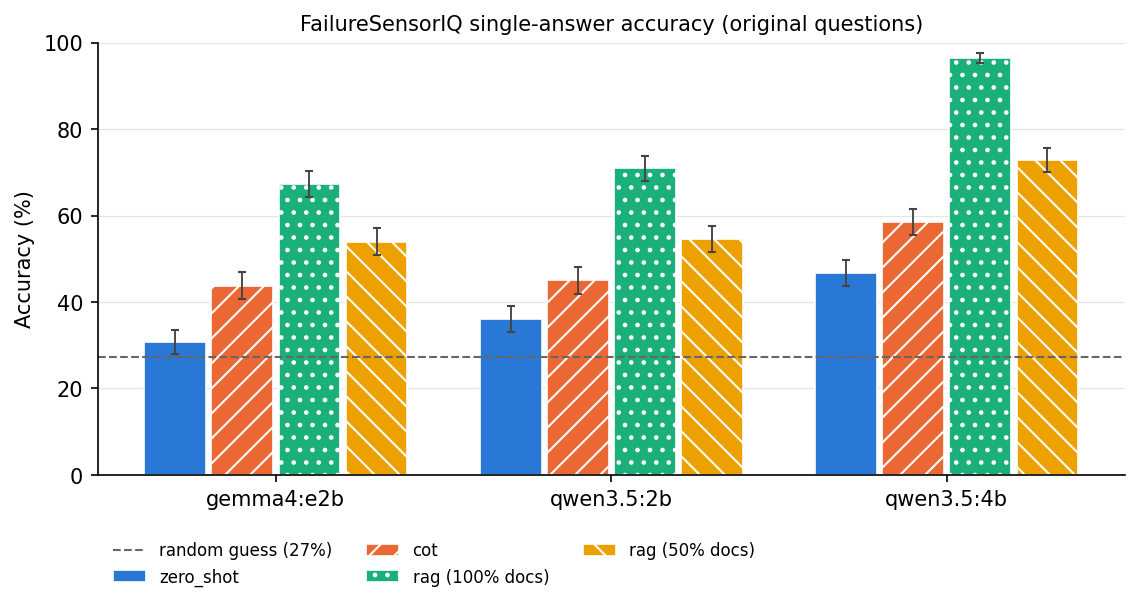

In [20]:
fig = plot_accuracy(summary, "original", path=os.path.join(DRIVE_DIR, "fig_accuracy_original.png"))
plt.show()

### Robustness: does the model still get it right when options are shuffled or the question is reworded?
Appears once the perturbed runs have finished.

In [21]:
cons = consistency(res)
if cons.empty:
    print("Robustness runs not finished yet.")
else:
    cons.to_csv(os.path.join(DRIVE_DIR, "summary_robustness.csv"), index=False)
    display(cons)

,model,method,n_common,acc_original,acc_simple_pert,acc_complex_pert,acc_consistent_all3
0,gemma4:e2b,rag (100% docs),1000,0.674,0.642,0.691,0.522
1,gemma4:e2b,zero_shot,1000,0.307,0.319,0.342,0.194
2,qwen3.5:2b,rag (100% docs),1000,0.710,0.598,0.592,0.468
3,qwen3.5:2b,zero_shot,1000,0.360,0.300,0.301,0.126
4,qwen3.5:4b,rag (100% docs),1000,0.966,0.964,0.963,0.929
5,qwen3.5:4b,zero_shot,1000,0.467,0.475,0.465,0.267


### Accuracy by asset
Shows where the models are weakest. Useful for the Discussion section.

In [22]:
by_asset = accuracy_by_asset(res, "original")
by_asset.to_csv(os.path.join(DRIVE_DIR, "summary_by_asset.csv"))
display(by_asset)

model                                    gemma4:e2b                  \
method                                          cot rag (100% docs)   
asset                                                                 
aero gas turbine                              0.373           0.627   
compressor                                    0.390           0.720   
electric generator                            0.523           0.739   
electric motor                                0.523           0.761   
fan                                           0.533           0.813   
industrial gas turbine                        0.522           0.722   
power transformer                             0.382           0.627   
pump                                          0.421           0.825   
reciprocating internal combustion engine      0.500           0.500   
steam turbine                                 0.234           0.625   

model                                                             qwen3.5:2b  \
method                                   rag (50% docs) zero_shot        cot   
asset                                                                          
aero gas turbine                                  0.500     0.278      0.341   
compressor                                        0.659     0.305      0.439   
electric generator                                0.625     0.284      0.534   
electric motor                                    0.614     0.364      0.557   
fan                                               0.587     0.320      0.520   
industrial gas turbine                            0.611     0.333      0.456   
power transformer                                 0.500     0.289      0.377   
pump                                              0.632     0.439      0.544   
reciprocating internal combustion engine          0.389     0.278      0.492   
steam turbine                                     0.438     0.266      0.391   

model                                                                    \
method                                   rag (100% docs) rag (50% docs)   
asset                                                                     
aero gas turbine                                   0.627          0.492   
compressor                                         0.768          0.671   
electric generator                                 0.830          0.682   
electric motor                                     0.830          0.636   
fan                                                0.813          0.627   
industrial gas turbine                             0.744          0.533   
power transformer                                  0.632          0.500   
pump                                               0.877          0.649   
reciprocating internal combustion engine           0.540          0.405   
steam turbine                                      0.734          0.438   

model                                              qwen3.5:4b                  \
method                                   zero_shot        cot rag (100% docs)   
asset                                                                           
aero gas turbine                             0.262      0.532           0.913   
compressor                                   0.378      0.488           0.988   
electric generator                           0.432      0.614           0.977   
electric motor                               0.420      0.557           1.000   
fan                                          0.467      0.653           1.000   
industrial gas turbine                       0.344      0.644           0.978   
power transformer                            0.270      0.632           0.966   
pump                                         0.404      0.491           1.000   
reciprocating internal combustion engine     0.429      0.651           0.937   
steam turbine                                0.359      0.469           0.953   

model

## 12. Next steps
1. **Laptop benchmark:** copy `sample_ids.csv` from Drive next to `fsiq_laptop_benchmark.py` and run it (instructions at the top of that file).
2. **Fine-tuning (QLoRA):** a separate notebook; train on 7 assets, test on the 3 held out, then compare with RAG on those same 3 assets.
3. **Write-up:** `summary_accuracy.csv`, `summary_robustness.csv` and `fig_accuracy_original.png` in your Drive folder are the paper's results tables and figure.